This is the linear regression model created for helping out Dino Tim
These are the following features in the data set - 
1. Date
2. high
3. low
4. momentum_index
5. beta_indicator
6. risk_premium
7. index
8. volatility_factor
9. technical_score
10. oscillator_value
11. liquidity_ratio
12. open
13. quant_index
14. trend_strength
15. market_sentiment
16. volume
17. alpha_signal


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


First we need to preprocess the data.

In [2]:
d1 = pd.read_csv("train.csv")

missing_values_count = d1.isnull().sum()
print(missing_values_count)
total_cells = np.prod(d1.shape)
total_missing = missing_values_count.sum()

# percent of data that is missing
percent_missing = (total_missing/total_cells) * 100
print(percent_missing)
d2 = d1.dropna()
d2 = d2.drop(d2[d2['close'] == 0].index)
print(d2)
missing_values_count = d2.isnull().sum()
print(missing_values_count)
percentage_data_gone = ((np.prod(d1.shape) - np.prod(d2.shape))/(np.prod(d1.shape))*100)
print(percentage_data_gone)

    

date                 1558
high                 1540
low                  1466
momentum_index       1455
beta_indicator       1439
risk_premium         1561
index                1521
volatility_factor    1519
technical_score      1514
oscillator_value     1465
liquidity_ratio      1513
open                 1440
quant_index          1572
trend_strength       1493
market_sentiment     1470
close                1510
volume               1490
alpha_signal         1455
symbols                 0
dtype: int64
0.5016347145129368
              date        high         low  momentum_index  beta_indicator  \
1       27-02-2013   84.148858   62.911473      123.066279       99.689780   
2       19-07-2010  162.714072    7.813419       50.140068      -30.373609   
3       31-12-2015 -128.017977  -38.679447      -21.881272     -173.386894   
4       12-11-2012  204.768157   -6.981525      -38.978256       64.867265   
5       27-04-2010   58.260369  -94.695877     -120.493850       68.088092   
...   

as the percentage missing data is just 0.5% i can just omit these values . we also checked with removing all the rows with missing values we still have a massive chunk of data left we also only lost 6.9% of data by removing all then null values

In [3]:

features = ["high", "low", 
            "momentum_index","beta_indicator","risk_premium","index","volatility_factor","technical_score","oscillator_value","liquidity_ratio","open","quant_index",
            "trend_strength","market_sentiment","volume","alpha_signal"]

X_train = d2[features].to_numpy().astype(float)
Y_train = d2['close'].to_numpy().astype(float)
print(X_train)
print(f" the shape of features are : {X_train.shape}")
print(Y_train)
print(f"The shape of the labels are: {Y_train.shape}")

[[ 8.41488580e+01  6.29114733e+01  1.23066279e+02 ...  2.21824044e+02
   2.43831000e+07 -2.21119843e+01]
 [ 1.62714072e+02  7.81341914e+00  5.01400680e+01 ...  5.88347326e+01
   3.81818000e+07  2.00686558e+01]
 [-1.28017977e+02 -3.86794470e+01 -2.18812724e+01 ...  1.37518347e+02
   9.44600000e+05  7.52971340e+01]
 ...
 [ 3.33263618e+01  1.98863154e+02  2.53656654e+02 ...  1.51052047e+02
   1.09870000e+06 -3.90693673e+01]
 [ 4.51780669e+01  8.05366960e+01  1.20597055e+02 ...  2.13625402e+02
   1.24190000e+06  1.31064198e+02]
 [ 1.19590844e+01  1.71348424e+02  2.19366743e+02 ... -1.36600823e+02
   6.83800000e+05 -1.26016342e+01]]
 the shape of features are : (262861, 16)
[27.41     25.23     30.       ... 63.900002 44.369999 61.470001]
The shape of the labels are: (262861,)


In [4]:
#now lets normalize the data
mean = np.mean(X_train, axis=0)
sd = np.std(X_train, axis = 0)
X_scaled =  (X_train - mean)/sd
print(X_scaled[:2])
print(X_scaled.shape)

[[ 0.17398947 -0.00591286  0.41706398  0.33861814  0.40172662 -1.08069903
   0.32716459 -0.50494845 -0.91868997 -1.20532656 -0.11635956  1.31999751
   0.74851078  1.04847871  1.52387452 -0.91482938]
 [ 0.91692375 -0.37525645 -0.1045347  -0.93132727  0.62361182  1.34893245
   1.49238624 -0.94523288 -1.05099727 -0.37596079  0.5694106  -1.47211957
   1.94336985 -0.03988982  2.63055222 -0.47180908]]
(262861, 16)


In [5]:
def prediction(x,w,b):
    final = np.dot(x,w) + b
    print(f"The predicted close price is {final}")

In [6]:
def compute_cost(x,y,w,b):
    m = x.shape[0]
    cost = 0
    cost = (np.dot(x,w) + b - y)**2
    cost = cost/(2*m)
    final_cost = np.sum(cost)
    return final_cost

In [14]:
def compute_gradient(x,y,w,b):
    m = x.shape[0]
    dj_dw = 0
    dj_db = 0
    dj_dw = np.dot((np.dot(x,w) + b-y),x)
    dj_db = np.sum((np.dot(x,w) + b - y))
    dj_dw = dj_dw/m
    dj_db = dj_db/m
    return dj_dw, dj_db


dj_dw ,dj_db = compute_gradient(X_scaled[:2,:],Y_train[:2],np.zeros(16),0)
print(dj_dw,dj_db)
print(dj_dw.shape)




[-13.95151885   4.81489583  -4.39715674   7.10793192 -13.37252644
  -2.20580263 -23.31024311  18.84443139  25.84897665  21.26174592
  -5.58840694   0.48022247 -34.77395086 -13.86619061 -54.06911652
  18.48960822] -26.32
(16,)


In [15]:
def gradient_descent(x,y,w,b,cost_function,gradient_function,alpha,num_iters):
    J_history  = []
    w_history = []
    b_history = []
    pred = []

    for i in range(num_iters):
        
        dj_dw, dj_db = gradient_function(x,y,w,b)
        w = w - alpha*dj_dw
        b = b - alpha*dj_db
        J_history.append(cost_function(x,y,w,b))
        w_history.append(w)
        b_history.append(b)
        pred.append(np.dot(x,w) + b)

    return w,b,J_history,w_history,b_history,pred

In [27]:
w_init = np.zeros(16)
b_init = 0
x = X_scaled
y = Y_train
w = w_init
b = b_init
alpha = 0.01
iterations = 2000
print(Y_train)
print(d2['close'])
zeroes = d2['close'].isnull().sum()
print(zeroes)
print("Number of zeros:", np.sum(Y_train == 0))
print("Actual zeros:", (d2['close'] == 0).sum())
w,b,J_history,w_history,b_history,pred = gradient_descent(X_scaled,Y_train,w_init,b_init,compute_cost,compute_gradient,alpha,iterations)
print(f"After gradient descent -  w = {w}, b = {b}")
print(J_history[:10])
accuracy  = ((pred - Y_train)/Y_train)*100
print(accuracy)
print(w.shape)

[27.41     25.23     30.       ... 63.900002 44.369999 61.470001]
1         27.410000
2         25.230000
3         30.000000
4         68.480003
5         43.209999
            ...    
283080    87.440070
283081    40.580002
283082    63.900002
283083    44.369999
283084    61.470001
Name: close, Length: 262861, dtype: float64
0
Number of zeros: 0
Actual zeros: 0
After gradient descent -  w = [ 3.66642438e+01  3.36557929e+01 -2.19740227e+01  2.52873166e+00
  1.27194333e+00 -1.64920456e-03 -2.27070759e+01  5.49770955e-01
  1.96331499e+00  2.91472326e+00  3.90173734e+01  7.64075064e-03
 -2.24847423e+01  9.56266054e-01 -1.89277519e-01  6.26890103e-01], b = 64.9640458964813
[np.float64(4655.966878890947), np.float64(4386.512672606771), np.float64(4141.325835104202), np.float64(3917.961668015857), np.float64(3714.2275634051393), np.float64(3528.1568902781473), np.float64(3357.985588507018), np.float64(3202.131189416623), np.float64(3059.1740113999276), np.float64(2927.8403050217166)]
[[ -9

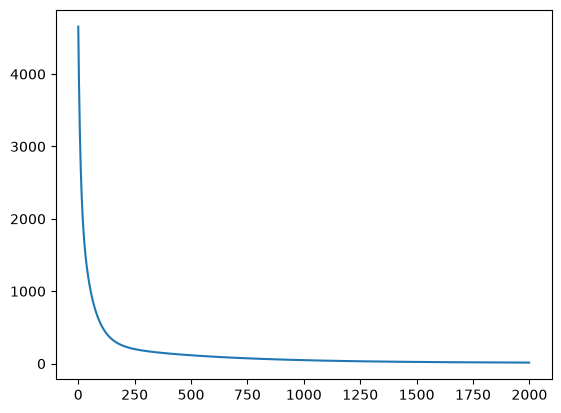

In [28]:
plt.plot(range(iterations),J_history)

plt.show()

In [32]:
d3 = pd.read_csv("test.csv")
test = d3.dropna()
test = test.drop(test[test['close'] == 0].index)
X_test = test[features].to_numpy().astype(float)
mean_t = np.mean(X_test,axis = 0)
std_t = np.std(X_test,axis = 0)
X_test_scaled = (X_test - mean_t)/(std_t)
Y_test = test['close'].to_numpy().astype(float)
zeroes = test['close'].isnull().count()
print(zeroes)
print(X_test_scaled.shape)
print(w.shape)
print(Y_test)

173375
(173375, 16)
(16,)
[ 42.099998   102.639999    46.150002   ... 103.160004    17.25333422
  19.99      ]


In [33]:
print(type(b))
print(np.shape(b))
print(b)
prediction = np.dot(X_test_scaled,w) + b
print(prediction)
accuracy = (1 - (np.abs(prediction - Y_test)/(Y_test)))*100
mean_accuracy  = np.mean(accuracy)
std_accuracy = np.std(accuracy)
print(f"The mean accuracy is: {mean_accuracy}")
print(f"The standard deviation of accuracy is: {std_accuracy}")


<class 'numpy.float64'>
()
64.9640458964813
[ 35.7596664  115.16595345  60.3744634  ...  91.34674043   1.60823818
  24.86057985]
The mean accuracy is: 71.145001714096
The standard deviation of accuracy is: 38.436637308975754
